# Stock Market Trend Prediction

Predicts whether a stock's closing price will go **UP or DOWN on the next trading day**, using historical daily prices of **NIFTY 50** stocks.

**Steps:** Load data → Clean → Feature engineering → Target → EDA → Time-based split → Train models → Evaluate vs baseline

**Data:** downloaded automatically with `yfinance` (needs internet the first time; then cached in `data/`).

## 1. Import libraries

In [18]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             f1_score, precision_score, recall_score)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
DATA, IMAGES = Path("data"), Path("images")
DATA.mkdir(exist_ok=True)
IMAGES.mkdir(exist_ok=True)

START_DATE = "2005-01-01"   # use "2015-01-01" for a quicker run
CSV_PATH = None             # or path to your own CSV: Date, Open, High, Low, Close, Volume[, Ticker]

In [19]:
pip install yfinance

  Using cached cffi-2.1.1-cp312-cp312-win_amd64.whl.metadata (2.6 kB)
Using cached cffi-2.1.1-cp312-cp312-win_amd64.whl (185 kB)
  Attempting uninstall: cffi
    Found existing installation: cffi 1.17.1
    Uninstalling cffi-1.17.1:
      Successfully uninstalled cffi-1.17.1
Note: you may need to restart the kernel to use updated packages.


  You can safely remove it manually.

[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


## 2. Load the data
Downloads daily prices for NIFTY 50 stocks from Yahoo Finance. The first run takes a few minutes; later runs use the saved CSV.

In [21]:
NIFTY50 = [
    "RELIANCE", "TCS", "HDFCBANK", "INFY", "ICICIBANK", "HINDUNILVR", "ITC", "SBIN", "BHARTIARTL",
    "KOTAKBANK", "LT", "AXISBANK", "ASIANPAINT", "MARUTI", "SUNPHARMA", "TITAN", "ULTRACEMCO",
    "BAJFINANCE", "WIPRO", "NESTLEIND", "HCLTECH", "TECHM", "POWERGRID", "NTPC", "ONGC",
    "TATASTEEL", "JSWSTEEL", "ADANIPORTS", "GRASIM", "COALINDIA", "BAJAJFINSV", "DRREDDY",
    "CIPLA", "DIVISLAB", "BRITANNIA", "EICHERMOT", "HEROMOTOCO", "HINDALCO", "INDUSINDBK",
    "TATAMOTORS", "TATACONSUM", "APOLLOHOSP", "BPCL", "SBILIFE", "HDFCLIFE", "UPL", "M&M",
    "BAJAJ-AUTO", "SHREECEM", "ADANIENT",
]

def download_data(tickers, start):
    import yfinance as yf
    frames = []
    for t in tickers:
        hist = yf.Ticker(f"{t}.NS").history(start=start, auto_adjust=True)
        if hist.empty:
            print(f"skipped {t} (no data)")
            continue
        hist = hist.reset_index()[["Date", "Open", "High", "Low", "Close", "Volume"]]
        hist["Ticker"] = t
        frames.append(hist)
    return pd.concat(frames, ignore_index=True)

cache = DATA / "nifty50_prices.csv"
if CSV_PATH:
    raw = pd.read_csv(CSV_PATH)
elif cache.exists():
    raw = pd.read_csv(cache)
    print("Loaded cached data")
else:
    raw = download_data(NIFTY50, START_DATE)
    raw.to_csv(cache, index=False)
if "Ticker" not in raw.columns:
    raw["Ticker"] = "STOCK"

print("Shape:", raw.shape)
raw.head()

Loaded cached data
Shape: (254034, 7)


,Date,Open,High,Low,Close,Volume,Ticker
0,2005-01-03 00:00:00+05:30,32.217323,32.551801,31.882844,32.483112,96188867,RELIANCE
1,2005-01-04 00:00:00+05:30,32.850458,32.850458,31.632005,31.730556,73639782,RELIANCE
2,2005-01-05 00:00:00+05:30,31.416975,31.861949,30.828654,31.652899,112450407,RELIANCE
3,2005-01-06 00:00:00+05:30,31.536439,32.044129,31.193000,31.428930,91978134,RELIANCE
4,2005-01-07 00:00:00+05:30,31.954531,32.713077,31.509557,32.387558,108134977,RELIANCE


## 3. Clean the data

In [23]:
print("Missing values:\n", raw.isnull().sum(), "\n")

df = raw.copy()
df["Date"] = pd.to_datetime(df["Date"], utc=True).dt.tz_localize(None).dt.normalize()
df = df.drop_duplicates(subset=["Ticker", "Date"])
df = df.dropna(subset=["Open", "High", "Low", "Close", "Volume"])
df = df[(df["Close"] > 0) & (df["Volume"] > 0)]
df = df.sort_values(["Ticker", "Date"]).reset_index(drop=True)

print(f"After cleaning: {len(df):,} rows (removed {len(raw) - len(df):,})")
print(f"Stocks: {df['Ticker'].nunique()} | Dates: {df['Date'].min().date()} to {df['Date'].max().date()}")
df.describe()

Missing values:
 Date      0
Open      0
High      0
Low       0
Close     0
Volume    0
Ticker    0
dtype: int64 

After cleaning: 252,219 rows (removed 1,815)
Stocks: 49 | Dates: 2005-01-02 to 2026-10-18


,Date,Open,High,Low,Close,Volume
count,252219,252219.000000,252219.000000,252219.000000,252219.000000,2.522190e+05
mean,2016-03-04 06:53:31.237853184,1125.943409,1139.451501,1111.362994,1125.142482,7.517808e+06
min,2005-01-02 00:00:00,0.407036,0.439512,0.391880,0.413098,6.800000e+01
25%,2010-11-03 00:00:00,115.482736,117.471896,113.307723,115.351387,8.195560e+05
50%,2016-04-25 00:00:00,337.662491,342.651018,332.458632,337.384003,2.679095e+06
75%,2021-08-02 00:00:00,1015.758376,1029.115540,1002.300719,1015.898071,8.100824e+06
max,2026-10-18 00:00:00,32314.193495,32314.193909,31493.657497,32169.978516,8.552157e+08
std,NaN,2709.041630,2740.362446,2674.387800,2706.671658,1.621964e+07


## 4. Feature engineering and target
Features are calculated **separately for each stock**, using only past and current prices:

| Feature | Meaning |
|---|---|
| `return_1d`, `return_5d` | % change over 1 and 5 days |
| `close_vs_ma5`, `close_vs_ma20`, `ma5_vs_ma20` | Price relative to its 5/20-day moving averages |
| `volatility_10d` | Standard deviation of daily returns over 10 days |
| `high_low_range`, `open_close_change` | Size of the day's price movement |
| `volume_vs_avg20` | Today's volume relative to the 20-day average |
| `rsi_14` | Relative Strength Index (momentum indicator) |
| `return_lag1..3` | Returns from the previous 1–3 days |

**Target:** `1` if tomorrow's close is higher than today's, otherwise `0`.

In [25]:
FEATURES = ["return_1d", "return_5d", "close_vs_ma5", "close_vs_ma20", "ma5_vs_ma20",
            "volatility_10d", "high_low_range", "open_close_change", "volume_vs_avg20", "rsi_14",
            "return_lag1", "return_lag2", "return_lag3"]

def rsi(close, period=14):
    delta = close.diff()
    gain = delta.clip(lower=0).rolling(period).mean()
    loss = (-delta.clip(upper=0)).rolling(period).mean()
    return 100 - 100 / (1 + gain / loss.replace(0, np.nan))

def add_features(g):
    g = g.copy()
    c = g["Close"]
    g["return_1d"] = c.pct_change()
    g["return_5d"] = c.pct_change(5)
    ma5, ma20 = c.rolling(5).mean(), c.rolling(20).mean()
    g["close_vs_ma5"] = c / ma5 - 1
    g["close_vs_ma20"] = c / ma20 - 1
    g["ma5_vs_ma20"] = ma5 / ma20 - 1
    g["volatility_10d"] = g["return_1d"].rolling(10).std()
    g["high_low_range"] = (g["High"] - g["Low"]) / c
    g["open_close_change"] = (c - g["Open"]) / g["Open"]
    g["volume_vs_avg20"] = g["Volume"] / g["Volume"].rolling(20).mean() - 1
    g["rsi_14"] = rsi(c)
    for lag in (1, 2, 3):
        g[f"return_lag{lag}"] = g["return_1d"].shift(lag)
    g["next_close"] = c.shift(-1)
    g["Target"] = (g["next_close"] > c).astype(int)
    return g

data = pd.concat([add_features(g) for _, g in df.groupby("Ticker")], ignore_index=True)
data = data.replace([np.inf, -np.inf], np.nan).dropna(subset=FEATURES + ["next_close"]).reset_index(drop=True)

print(f"Feature table: {len(data):,} rows x {len(FEATURES)} features")
print(f"UP days: {data['Target'].mean():.1%} | DOWN days: {1 - data['Target'].mean():.1%}")
data[["Date", "Ticker", "Close"] + FEATURES + ["Target"]].head()

Feature table: 251,229 rows x 13 features
UP days: 50.8% | DOWN days: 49.2%


,Date,Ticker,Close,return_1d,return_5d,close_vs_ma5,close_vs_ma20,ma5_vs_ma20,volatility_10d,high_low_range,open_close_change,volume_vs_avg20,rsi_14,return_lag1,return_lag2,return_lag3,Target
0,2005-01-31,ADANIENT,4.313175,-0.009960,0.041201,0.007024,0.015218,0.008137,0.013044,0.036888,-0.009960,-0.035750,50.000000,0.003331,0.019009,0.028631,1
1,2005-02-01,ADANIENT,4.376817,0.014755,0.056564,0.010823,0.031708,0.020662,0.012140,0.031725,0.000661,0.188434,59.450311,-0.009960,0.003331,0.019009,1
2,2005-02-02,ADANIENT,4.440459,0.014541,0.042091,0.017095,0.046924,0.029328,0.012471,0.028664,0.000652,0.108834,74.144565,0.014755,-0.009960,0.003331,0
3,2005-02-03,ADANIENT,4.411530,-0.006515,0.015990,0.007265,0.038722,0.031230,0.012713,0.041312,-0.033587,0.030619,63.033127,0.014541,0.014755,-0.009960,0
4,2005-02-06,ADANIENT,4.344996,-0.015082,-0.002656,-0.007401,0.021804,0.029423,0.013852,0.033289,-0.015082,-0.044834,61.290460,-0.006515,0.014541,0.014755,1


## 5. Exploratory Data Analysis
### 5.1 Price trends (normalised to 100 at the start)

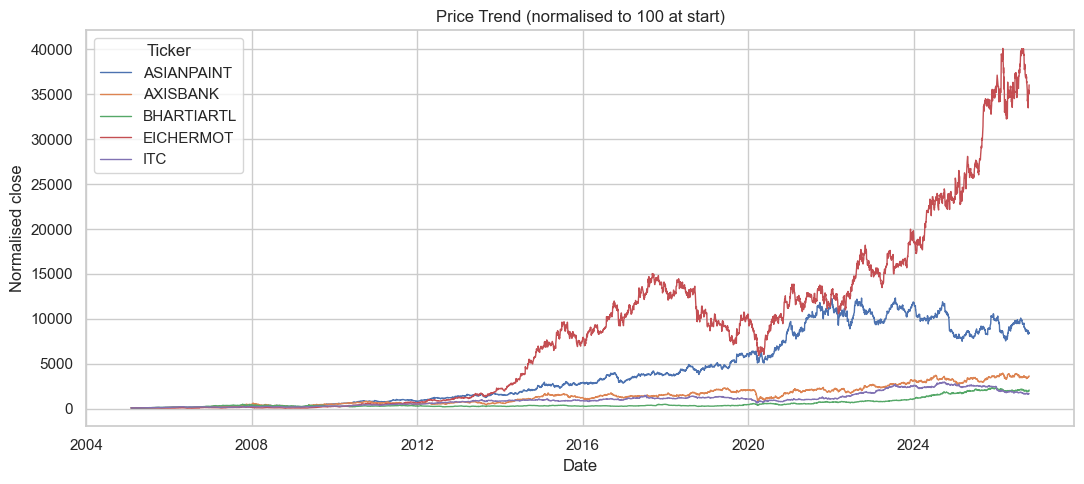

In [27]:
top = data["Ticker"].value_counts().index[:5]
trend = data[data["Ticker"].isin(top)].copy()
trend["Normalised"] = trend.groupby("Ticker")["Close"].transform(lambda s: s / s.iloc[0] * 100)

plt.figure(figsize=(11, 5))
sns.lineplot(x="Date", y="Normalised", hue="Ticker", data=trend, linewidth=1)
plt.title("Price Trend (normalised to 100 at start)")
plt.ylabel("Normalised close")
plt.tight_layout()
plt.savefig(IMAGES / "price_trend.png", dpi=120)
plt.show()

### 5.2 Distribution of daily returns

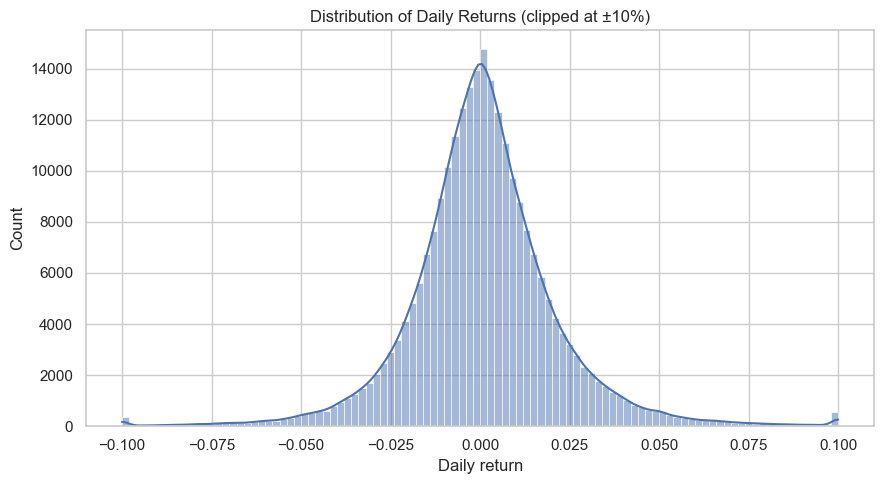

In [29]:
plt.figure(figsize=(9, 5))
sns.histplot(data["return_1d"].clip(-0.1, 0.1), bins=100, kde=True, color="#4C72B0")
plt.title("Distribution of Daily Returns (clipped at ±10%)")
plt.xlabel("Daily return")
plt.tight_layout()
plt.savefig(IMAGES / "returns_distribution.png", dpi=120)
plt.show()

### 5.3 UP vs DOWN days (class balance)

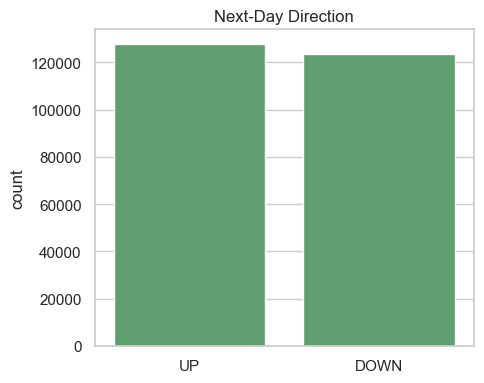

In [31]:
plt.figure(figsize=(5, 4))
sns.countplot(x=data["Target"].map({0: "DOWN", 1: "UP"}), color="#55A868")
plt.title("Next-Day Direction")
plt.xlabel("")
plt.tight_layout()
plt.show()

### 5.4 Feature correlation
Very low correlation between the features and `Target` is expected: next-day price direction is close to random.

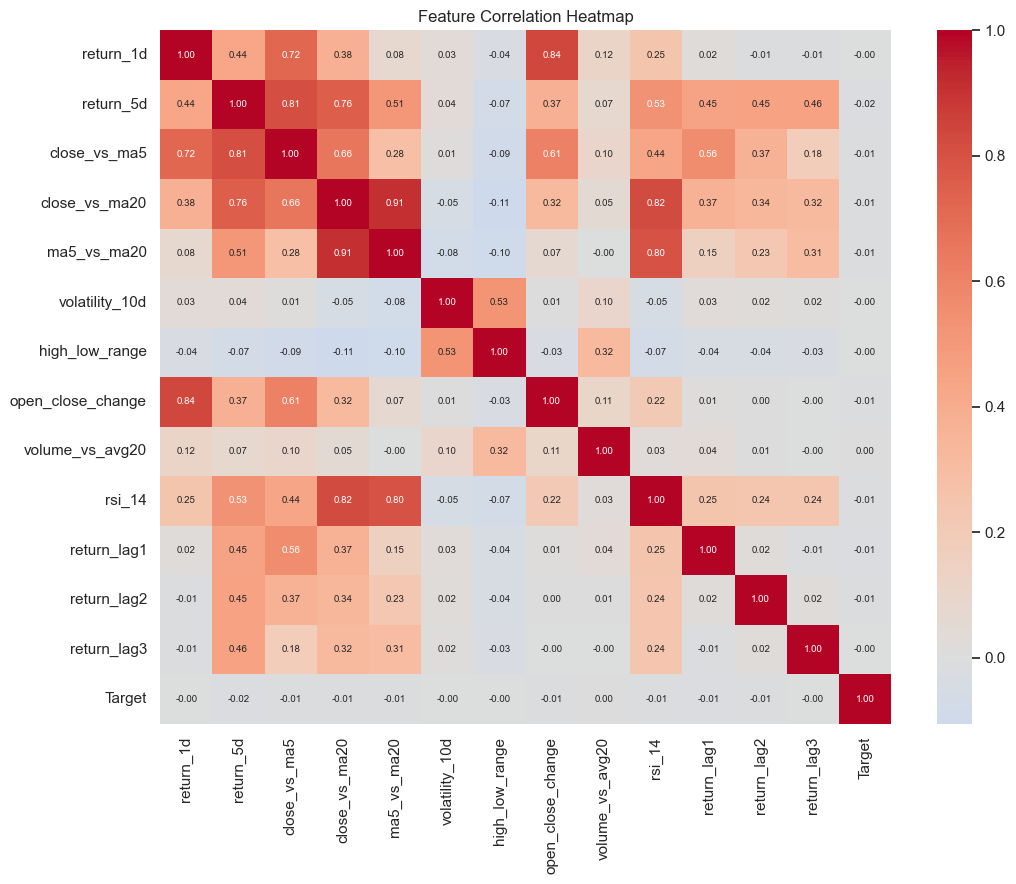

return_5d           -0.015171
return_lag1         -0.014712
close_vs_ma5        -0.012554
close_vs_ma20       -0.011726
rsi_14              -0.010056
ma5_vs_ma20         -0.007816
open_close_change   -0.007687
return_lag2         -0.006807
return_lag3         -0.004382
return_1d           -0.001829
volatility_10d      -0.000503
high_low_range      -0.000074
volume_vs_avg20      0.004862
Name: Target, dtype: float64

In [33]:
corr = data[FEATURES + ["Target"]].corr()
plt.figure(figsize=(11, 9))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, annot_kws={"size": 7})
plt.title("Feature Correlation Heatmap")
plt.tight_layout()
plt.savefig(IMAGES / "correlation_heatmap.png", dpi=120)
plt.show()

corr["Target"].drop("Target").sort_values()

## 6. Time-based train/test split
Train on the **earliest 80% of dates** and test on the **latest 20%**. The data is **not shuffled**: a random split would let the model learn from future prices, which gives unrealistically high scores.

In [35]:
dates = np.sort(data["Date"].unique())
cutoff = dates[int(len(dates) * 0.8)]
train, test = data[data["Date"] < cutoff], data[data["Date"] >= cutoff]

X_train, y_train = train[FEATURES], train["Target"]
X_test, y_test = test[FEATURES], test["Target"]
print(f"Train: {len(train):,} rows (before {pd.Timestamp(cutoff).date()})")
print(f"Test:  {len(test):,} rows (from {pd.Timestamp(cutoff).date()})")

Train: 198,805 rows (before 2022-06-15)
Test:  52,424 rows (from 2022-06-15)


## 7. Train and compare models
- **Baseline:** always predict the most common class. A model is only useful if it beats this.
- Logistic Regression and SVM are sensitive to feature scale, so they use `StandardScaler`. Random Forest does not need scaling.

In [37]:
def scores(name, y_true, y_pred):
    return {"Model": name, "Accuracy": accuracy_score(y_true, y_pred),
            "Precision": precision_score(y_true, y_pred, zero_division=0),
            "Recall": recall_score(y_true, y_pred, zero_division=0),
            "F1-score": f1_score(y_true, y_pred, zero_division=0)}

majority = int(y_train.mean() >= 0.5)
rows = [scores(f"Baseline (always {'UP' if majority else 'DOWN'})", y_test, np.full(len(y_test), majority))]

models = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "SVM (Linear)": make_pipeline(StandardScaler(), LinearSVC()),
    "Random Forest": RandomForestClassifier(n_estimators=200, max_depth=10, min_samples_leaf=50,
                                            random_state=RANDOM_STATE, n_jobs=-1),
}
predictions = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    predictions[name] = model.predict(X_test)
    rows.append(scores(name, y_test, predictions[name]))
    print(f"Trained {name}")

results = pd.DataFrame(rows)
results.round(4).to_csv(IMAGES / "model_results.csv", index=False)
results.round(4)

Trained Logistic Regression
Trained SVM (Linear)
Trained Random Forest


,Model,Accuracy,Precision,Recall,F1-score
0,Baseline (always UP),0.5106,0.5106,1.0000,0.6760
1,Logistic Regression,0.5094,0.5112,0.8918,0.6499
2,SVM (Linear),0.5097,0.5114,0.8906,0.6497
3,Random Forest,0.5076,0.5121,0.7513,0.6091


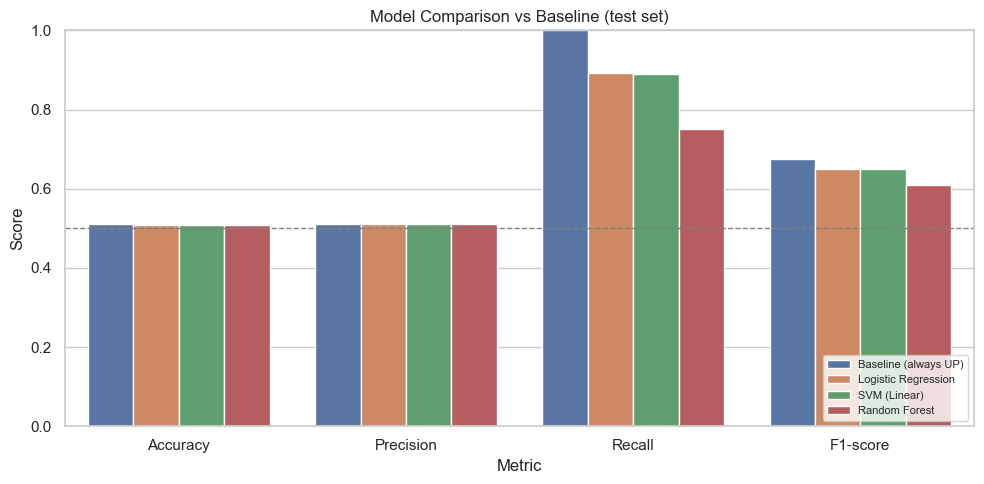

In [38]:
plt.figure(figsize=(10, 5))
sns.barplot(x="Metric", y="Score", hue="Model",
            data=results.melt(id_vars="Model", var_name="Metric", value_name="Score"))
plt.axhline(0.5, ls="--", c="grey", lw=1)
plt.ylim(0, 1)
plt.title("Model Comparison vs Baseline (test set)")
plt.legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.savefig(IMAGES / "model_comparison.png", dpi=120)
plt.show()

## 8. Evaluate the best model

Best model by F1-score: Logistic Regression 

              precision    recall  f1-score   support

        DOWN       0.49      0.11      0.18     25658
          UP       0.51      0.89      0.65     26766

    accuracy                           0.51     52424
   macro avg       0.50      0.50      0.42     52424
weighted avg       0.50      0.51      0.42     52424



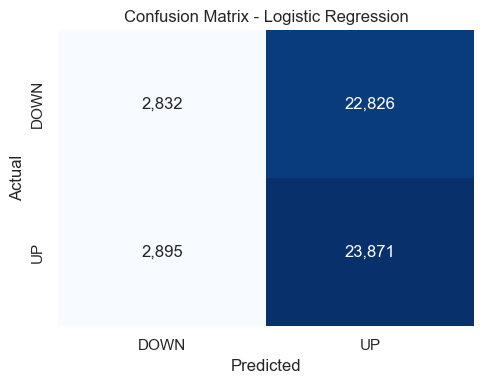

In [40]:
best_name = (results[~results["Model"].str.startswith("Baseline")]
             .sort_values("F1-score", ascending=False).iloc[0]["Model"])
print("Best model by F1-score:", best_name, "\n")
print(classification_report(y_test, predictions[best_name], target_names=["DOWN", "UP"], zero_division=0))

cm = confusion_matrix(y_test, predictions[best_name])
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt=",d", cmap="Blues", cbar=False,
            xticklabels=["DOWN", "UP"], yticklabels=["DOWN", "UP"])
plt.title(f"Confusion Matrix - {best_name}")
plt.xlabel("Predicted"); plt.ylabel("Actual")
plt.tight_layout()
plt.savefig(IMAGES / "confusion_matrix.png", dpi=120)
plt.show()

## 9. Which features matter most? (Random Forest)

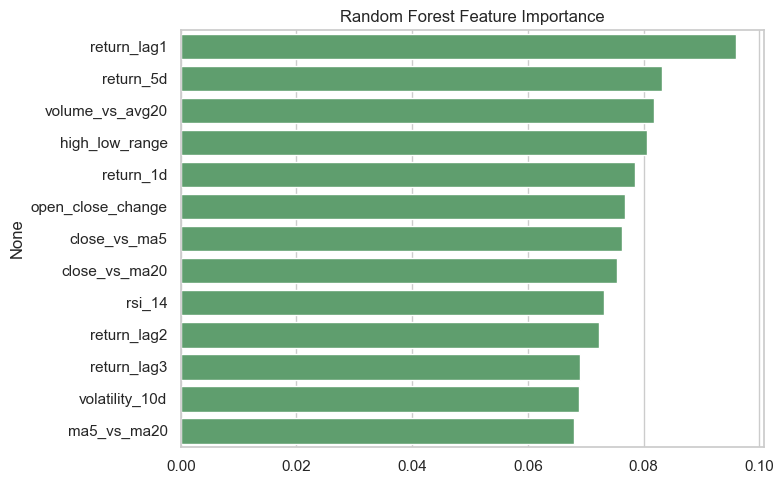

In [42]:
importance = pd.Series(models["Random Forest"].feature_importances_, index=FEATURES).sort_values(ascending=False)
plt.figure(figsize=(8, 5))
sns.barplot(x=importance.values, y=importance.index, color="#55A868")
plt.title("Random Forest Feature Importance")
plt.tight_layout()
plt.savefig(IMAGES / "feature_importance.png", dpi=120)
plt.show()

## Conclusion
- Engineered 13 technical features from daily NIFTY 50 prices and trained **Logistic Regression, SVM and Random Forest**.
- Used a **time-based split** to avoid look-ahead bias, and compared every model against a baseline.
- Accuracy around **50–55%** is normal for next-day direction; much higher results usually indicate data leakage.
- **Next steps:** add market-wide features (NIFTY index, sector), predict multi-day trends, try gradient boosting (XGBoost/LightGBM), or use walk-forward validation.